Appareil utilisé : cpu
Taille entraînement : 60000
Taille test         : 10000
Forme d'une image   : torch.Size([1, 28, 28])
Pixels min / max    : 0.0 1.0


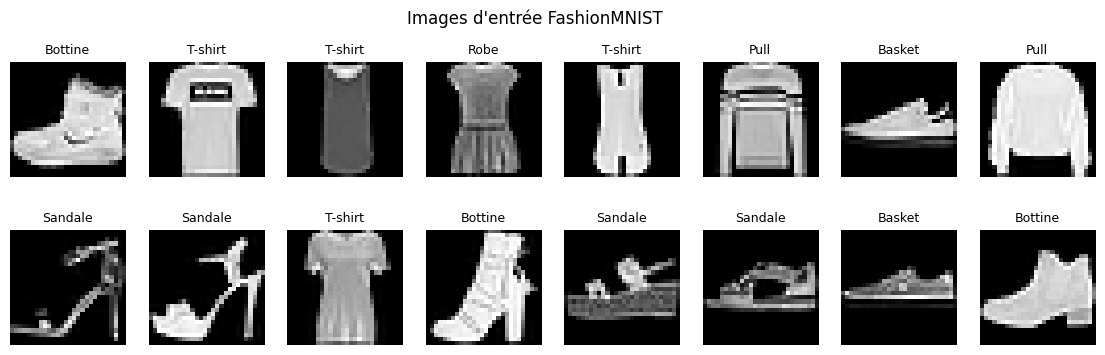

In [3]:
# =====================================================
# TP 2 — Auto-encodeurs, VAE, CVAE et PixelCNN
# Imports et configuration
# =====================================================
import torch                                     # calcul tensoriel et gradients automatiques
import torch.nn as nn                            # couches de réseaux de neurones
import torch.nn.functional as F                  # fonctions (BCE, one_hot, ...)
import torch.optim as optim                      # optimiseurs (Adam)
from torch.utils.data import DataLoader          # découpe des données en mini-lots
import torchvision                               # jeux de données d'images
import torchvision.transforms as transforms      # transformations des images
import numpy as np                               # calcul numérique
import matplotlib.pyplot as plt                  # graphiques

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

# =====================================================
# Bloc A — 1.1 AE dense — Question 1 : charger FashionMNIST
# =====================================================
transform = transforms.ToTensor()                # image -> tenseur, pixels entre 0 et 1
train_set = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_set = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=0)    # lots de 128 images
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=0)

classes = ["T-shirt", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Basket", "Sac", "Bottine"]

print("Taille entraînement :", len(train_set))
print("Taille test         :", len(test_set))
x, y = train_set[0]
print("Forme d'une image   :", x.shape)
print("Pixels min / max    :", x.min().item(), x.max().item())

fig, axes = plt.subplots(2, 8, figsize=(14, 4))  # visualisation : images d'entrée
for i, ax in enumerate(axes.flat):
    img, label = train_set[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(classes[label], fontsize=9)
    ax.axis("off")
plt.suptitle("Images d'entrée FashionMNIST")
plt.show()

In [4]:
# =====================================================
# Bloc A — 1.1 — Question 2 : encodeur dense  28x28 -> 1024 -> 256 -> 128
# =====================================================
class EncodeurDense(nn.Module):                 # E : R^784 -> R^128
    def __init__(self, latent_dim=128):
        super().__init__()
        self.reseau = nn.Sequential(
            nn.Flatten(),                       # (batch, 1, 28, 28) -> (batch, 784)
            nn.Linear(28 * 28, 1024), nn.ReLU(),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, latent_dim),         # pas d'activation : z peut être négatif
        )
    def forward(self, x):
        return self.reseau(x)                   # z = E(x)

# =====================================================
# Bloc A — 1.1 — Question 3 : décodeur symétrique  128 -> 256 -> 1024 -> 28x28 + Sigmoïde
# =====================================================
class DecodeurDense(nn.Module):                 # D : R^128 -> R^784
    def __init__(self, latent_dim=128):
        super().__init__()
        self.reseau = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 1024), nn.ReLU(),
            nn.Linear(1024, 28 * 28),
            nn.Sigmoid(),                       # pixels entre 0 et 1
        )
    def forward(self, z):
        return self.reseau(z).view(-1, 1, 28, 28)   # remise en forme d'image

# ---- Tests rapides (réseaux non entraînés) ----
x_batch, _ = next(iter(train_loader))
z = EncodeurDense()(x_batch)
x_rec = DecodeurDense()(z)
print("Forme de l'entrée x   :", x_batch.shape)
print("Forme du code z       :", z.shape)
print("Forme de la sortie x' :", x_rec.shape)
print("Paramètres encodeur :", sum(p.numel() for p in EncodeurDense().parameters()),
      "| décodeur :", sum(p.numel() for p in DecodeurDense().parameters()))

Forme de l'entrée x   : torch.Size([128, 1, 28, 28])
Forme du code z       : torch.Size([128, 128])
Forme de la sortie x' : torch.Size([128, 1, 28, 28])
Paramètres encodeur : 1099136 | décodeur : 1099792


[AE dense] Époque 1/5 | perte train = 0.0310 | perte test = 0.0190
[AE dense] Époque 2/5 | perte train = 0.0168 | perte test = 0.0151
[AE dense] Époque 3/5 | perte train = 0.0141 | perte test = 0.0133
[AE dense] Époque 4/5 | perte train = 0.0125 | perte test = 0.0120
[AE dense] Époque 5/5 | perte train = 0.0114 | perte test = 0.0111


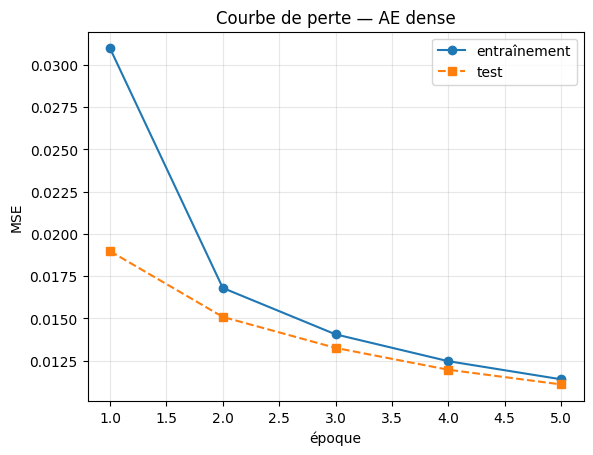

In [5]:
# =====================================================
# Bloc A — 1.1 — Question 4 : entraînement de l'AE dense avec MSELoss
# =====================================================
class AutoEncodeurDense(nn.Module):             # H = D ∘ E
    def __init__(self, latent_dim=128):
        super().__init__()
        self.encodeur = EncodeurDense(latent_dim)
        self.decodeur = DecodeurDense(latent_dim)
    def forward(self, x):
        return self.decodeur(self.encodeur(x))  # x' = D(E(x))

def entrainer_ae(modele, nb_epoques=5, lr=1e-3, nom="AE"):
    critere = nn.MSELoss()                      # perte de reconstruction : moyenne de (x' - x)²
    optimizer = optim.Adam(modele.parameters(), lr=lr)
    hist_train, hist_test = [], []
    for epoque in range(nb_epoques):
        modele.train(); s = 0.0
        for x, _ in train_loader:               # étiquettes ignorées : apprentissage non supervisé
            x = x.to(device)
            perte = critere(modele(x), x)       # la cible est l'image elle-même
            optimizer.zero_grad(); perte.backward(); optimizer.step()
            s += perte.item() * x.size(0)
        hist_train.append(s / len(train_set))
        modele.eval(); s = 0.0
        with torch.no_grad():
            for x, _ in test_loader:
                x = x.to(device)
                s += critere(modele(x), x).item() * x.size(0)
        hist_test.append(s / len(test_set))
        print(f"[{nom}] Époque {epoque+1}/{nb_epoques} | perte train = {hist_train[-1]:.4f} | perte test = {hist_test[-1]:.4f}")
    return hist_train, hist_test

torch.manual_seed(0)
ae_dense = AutoEncodeurDense().to(device)
hist_train, hist_test = entrainer_ae(ae_dense, nom="AE dense")

# ---- Visualisation attendue : courbe de perte ----
ep = range(1, len(hist_train) + 1)
plt.plot(ep, hist_train, "o-", label="entraînement")
plt.plot(ep, hist_test, "s--", label="test")
plt.xlabel("époque"); plt.ylabel("MSE"); plt.title("Courbe de perte — AE dense")
plt.legend(); plt.grid(alpha=0.3); plt.show()

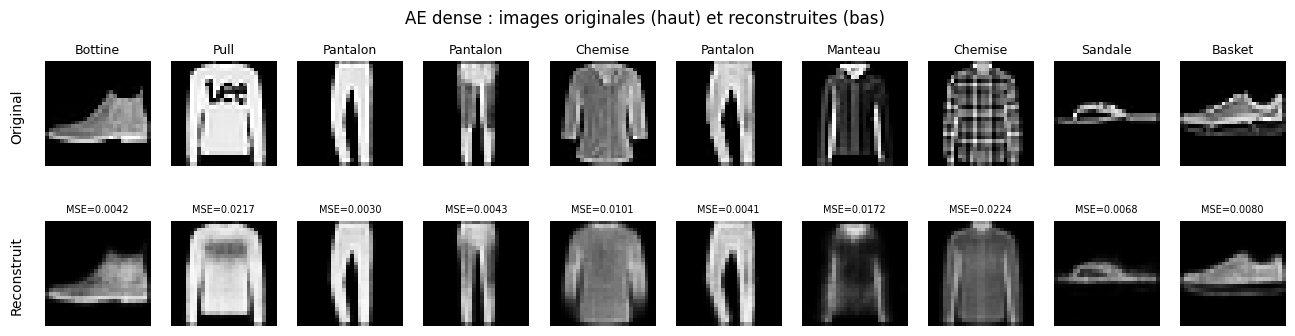

In [6]:
# =====================================================
# Bloc A — 1.1 — Question 5 : afficher quelques reconstructions
# =====================================================
def afficher_lignes(lignes, titre, n=10, etiquettes=None, ref=None):
    # lignes = liste de (nom, images) ; ref = images de référence pour calculer la MSE de chaque image
    fig, axes = plt.subplots(len(lignes), n, figsize=(16, 1.9 * len(lignes)))
    for r, (nom, images) in enumerate(lignes):
        for i in range(n):
            ax = axes[r, i]
            ax.imshow(images[i].cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
            if r == 0 and etiquettes is not None:
                ax.set_title(classes[etiquettes[i]], fontsize=9)                 # nom du vêtement
            elif ref is not None and r > 0:
                ax.set_title(f"MSE={((images[i] - ref[i])**2).mean().item():.4f}", fontsize=7)
            ax.axis("off")
        axes[r, 0].text(-8, 14, nom, fontsize=10, rotation=90, va="center", ha="center")
    plt.suptitle(titre); plt.show()

ae_dense.eval()
x_test, y_test = next(iter(test_loader))         # premier lot de 128 images de test
x_test = x_test.to(device)
with torch.no_grad():
    rec_dense = ae_dense(x_test)                 # reconstructions x' = D(E(x))
afficher_lignes([("Original", x_test), ("Reconstruit", rec_dense)],
                "AE dense : images originales (haut) et reconstruites (bas)",
                etiquettes=y_test, ref=x_test)

Forme des codes latents : (2000, 128)


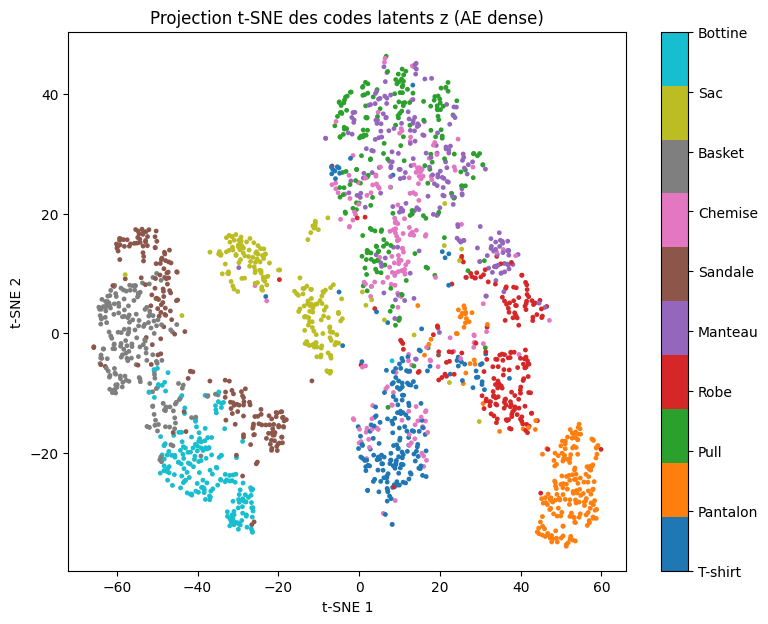

In [7]:
# =====================================================
# Bloc A — 1.1 — Visualisation : projection t-SNE des codes latents
# =====================================================
from sklearn.manifold import TSNE

def codes_latents(fonction_code, n_max=2000):
    # calcule les codes latents de n_max images de test (et garde leurs vraies classes pour colorer)
    codes, etiquettes = [], []
    with torch.no_grad():
        for x, y in test_loader:
            codes.append(fonction_code(x.to(device)).cpu()); etiquettes.append(y)
            if sum(len(c) for c in codes) >= n_max:
                break
    return torch.cat(codes)[:n_max].numpy(), torch.cat(etiquettes)[:n_max].numpy()

def afficher_tsne(codes, etiquettes, titre):
    codes_2d = TSNE(n_components=2, random_state=0).fit_transform(codes)   # projection en 2D
    plt.figure(figsize=(9, 7))
    nuage = plt.scatter(codes_2d[:, 0], codes_2d[:, 1], c=etiquettes, cmap="tab10", s=6)
    cbar = plt.colorbar(nuage, ticks=range(10)); cbar.ax.set_yticklabels(classes)
    plt.title(titre); plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2"); plt.show()

ae_dense.eval()
codes, etiquettes = codes_latents(ae_dense.encodeur)
print("Forme des codes latents :", codes.shape)
afficher_tsne(codes, etiquettes, "Projection t-SNE des codes latents z (AE dense)")

In [9]:
# =====================================================
# Bloc A — 1.2 — Question 1 : encodeur avec deux Conv2d de stride 2 (28 -> 14 -> 7)
# Bloc A — 1.2 — Question 2 : couche linéaire vers l'espace latent de dimension latent_dimension
# =====================================================
latent_dimension = 128                           # même taille que l'AE dense (comparaison équitable)

class EncodeurConv(nn.Module):
    def __init__(self, latent_dim=latent_dimension):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1), nn.ReLU(),    # 1x28x28  -> 32x14x14
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), nn.ReLU(),   # 32x14x14 -> 64x7x7
        )
        self.aplatir = nn.Flatten()                                # 64x7x7 -> 3136
        self.vers_latent = nn.Linear(64 * 7 * 7, latent_dim)       # Q2 : 3136 -> 128
    def forward(self, x):
        return self.vers_latent(self.aplatir(self.conv(x)))

# =====================================================
# Bloc A — 1.2 — Question 3 : décodeur symétrique avec ConvTranspose2d (7 -> 14 -> 28)
# =====================================================
class DecodeurConv(nn.Module):
    def __init__(self, latent_dim=latent_dimension):
        super().__init__()
        self.depuis_latent = nn.Sequential(nn.Linear(latent_dim, 64 * 7 * 7), nn.ReLU())   # 128 -> 3136
        self.remettre_en_forme = nn.Unflatten(1, (64, 7, 7))                                 # 3136 -> 64x7x7
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # -> 32x14x14
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1),              # -> 1x28x28
            nn.Sigmoid(),                                                                     # pixels entre 0 et 1
        )
    def forward(self, z):
        return self.deconv(self.remettre_en_forme(self.depuis_latent(z)))

# ---- Suivi des tailles couche par couche ----
enc, dec = EncodeurConv(), DecodeurConv()
h = x_batch
print("Entrée                 :", h.shape)
for couche in enc.conv:
    h = couche(h)
    if isinstance(couche, nn.Conv2d):
        print(f"Après Conv2d ({couche.in_channels}->{couche.out_channels})  :", h.shape)
z = enc(x_batch)
print("Code z                 :", z.shape)
print("Sortie du décodeur x'  :", dec(z).shape)
print("Paramètres encodeur conv :", sum(p.numel() for p in enc.parameters()),
      "| décodeur conv :", sum(p.numel() for p in dec.parameters()))

Entrée                 : torch.Size([128, 1, 28, 28])
Après Conv2d (1->32)  : torch.Size([128, 32, 14, 14])
Après Conv2d (32->64)  : torch.Size([128, 64, 7, 7])
Code z                 : torch.Size([128, 128])
Sortie du décodeur x'  : torch.Size([128, 1, 28, 28])
Paramètres encodeur conv : 420352 | décodeur conv : 423297


Paramètres AE conv  : 843649
Paramètres AE dense : 2198928
[AE conv] Époque 1/5 | perte train = 0.0218 | perte test = 0.0105
[AE conv] Époque 2/5 | perte train = 0.0087 | perte test = 0.0075
[AE conv] Époque 3/5 | perte train = 0.0067 | perte test = 0.0061
[AE conv] Époque 4/5 | perte train = 0.0056 | perte test = 0.0054
[AE conv] Époque 5/5 | perte train = 0.0050 | perte test = 0.0048


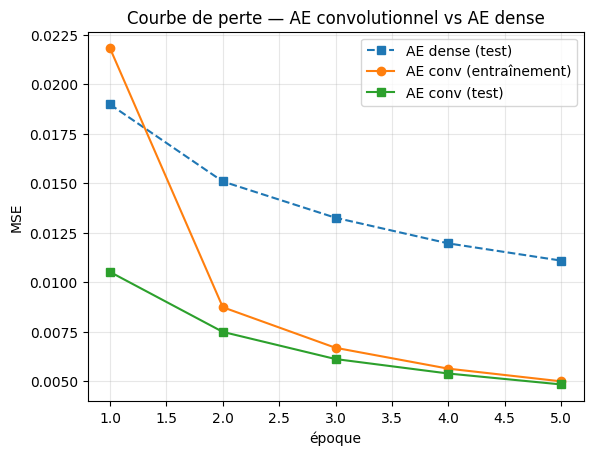

In [10]:
# =====================================================
# Bloc A — 1.2 — Question 4 : entraînement de l'AE convolutionnel sur FashionMNIST
# =====================================================
class AutoEncodeurConv(nn.Module):              # H = D ∘ E, version convolutionnelle
    def __init__(self, latent_dim=latent_dimension):
        super().__init__()
        self.encodeur = EncodeurConv(latent_dim)
        self.decodeur = DecodeurConv(latent_dim)
    def forward(self, x):
        return self.decodeur(self.encodeur(x))

torch.manual_seed(0)
ae_conv = AutoEncodeurConv().to(device)
print("Paramètres AE conv  :", sum(p.numel() for p in ae_conv.parameters()))
print("Paramètres AE dense :", sum(p.numel() for p in ae_dense.parameters()))
hist_train_conv, hist_test_conv = entrainer_ae(ae_conv, nom="AE conv")      # même fonction que l'AE dense

ep = range(1, len(hist_test_conv) + 1)
plt.plot(ep, hist_test, "s--", label="AE dense (test)")
plt.plot(ep, hist_train_conv, "o-", label="AE conv (entraînement)")
plt.plot(ep, hist_test_conv, "s-", label="AE conv (test)")
plt.xlabel("époque"); plt.ylabel("MSE"); plt.title("Courbe de perte — AE convolutionnel vs AE dense")
plt.legend(); plt.grid(alpha=0.3); plt.show()

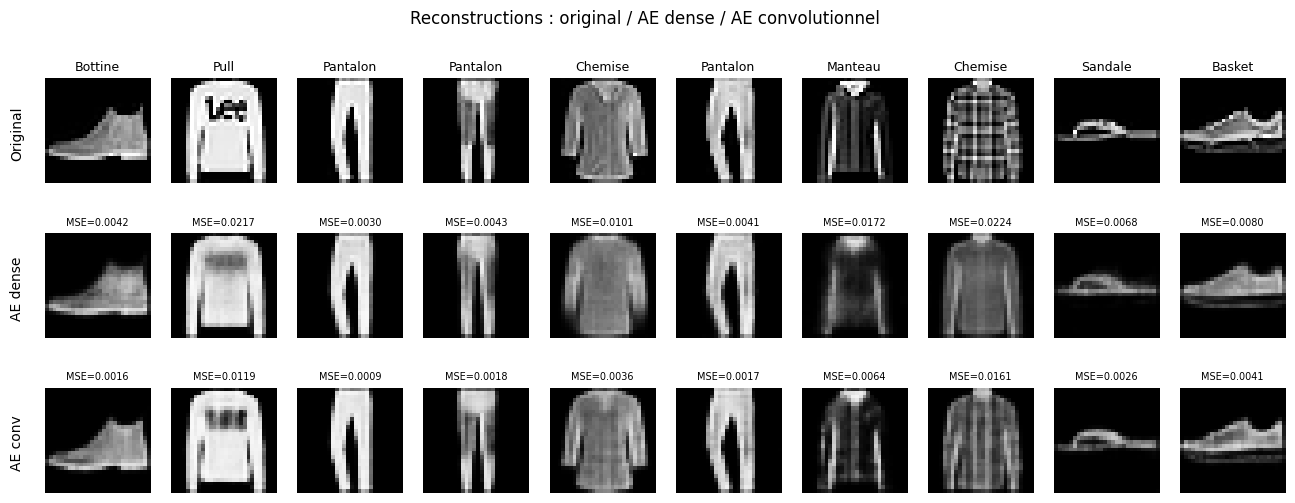

MSE moyenne test — AE dense : 0.0111
MSE moyenne test — AE conv  : 0.0048


In [11]:
# =====================================================
# Bloc A — 1.2 — Question 5 : comparaison qualitative AE dense / AE convolutionnel
# =====================================================
ae_dense.eval(); ae_conv.eval()
with torch.no_grad():
    rec_dense = ae_dense(x_test)                 # reconstructions de l'AE dense
    rec_conv = ae_conv(x_test)                   # reconstructions de l'AE convolutionnel
afficher_lignes([("Original", x_test), ("AE dense", rec_dense), ("AE conv", rec_conv)],
                "Reconstructions : original / AE dense / AE convolutionnel",
                etiquettes=y_test, ref=x_test)
print(f"MSE moyenne test — AE dense : {hist_test[-1]:.4f}")
print(f"MSE moyenne test — AE conv  : {hist_test_conv[-1]:.4f}")

Pixels min / max avant troncature : -1.238 2.14
Pixels min / max après troncature : 0.0 1.0
MSE  x̃    vs x    : 0.0521   (image bruitée, sans débruitage)
MSE  H(x̃) vs x    : 0.0203   (reconstruction de l'image bruitée)
MSE  H(x)  vs x    : 0.0045   (reconstruction de l'image propre)
MSE  H(x̃) vs H(x) : 0.0160


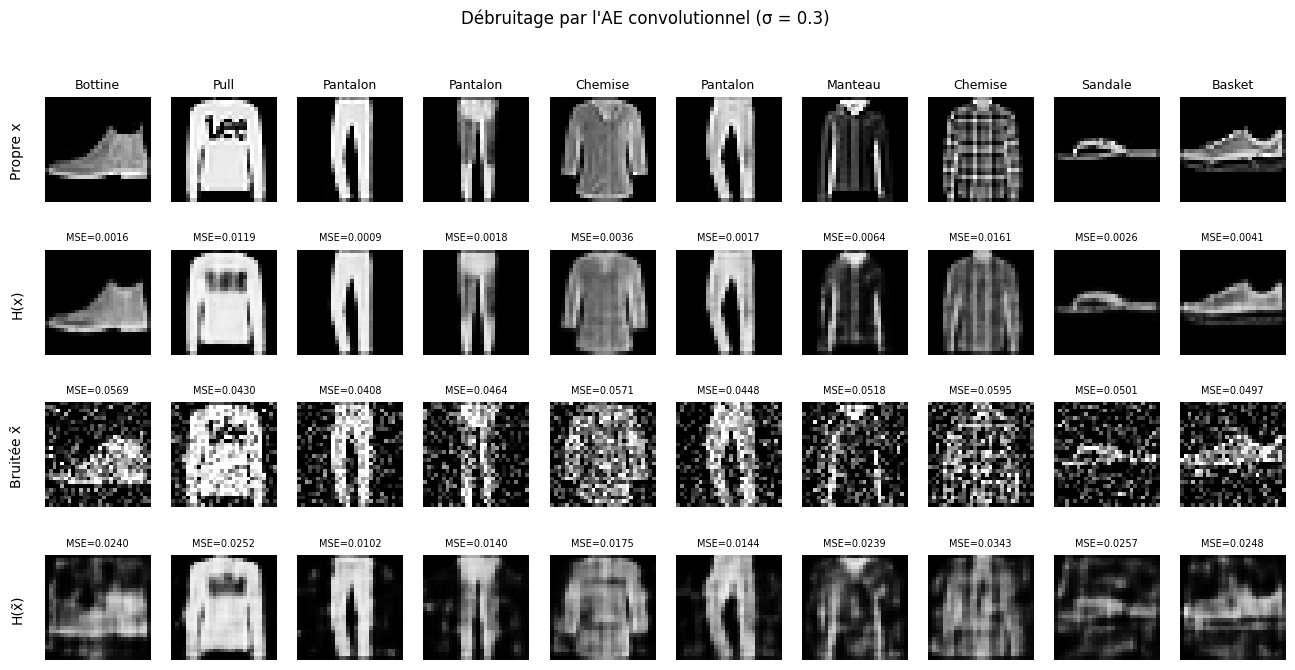

In [12]:
# =====================================================
# Bloc A — 1.3 — Question 1 : bruit gaussien  x̃ = x + ε,  ε ~ N(0, σ²)
# =====================================================
torch.manual_seed(0)
sigma_bruit = 0.3                                # amplitude du bruit
x_bruit = x_test + sigma_bruit * torch.randn_like(x_test)
print("Pixels min / max avant troncature :", round(x_bruit.min().item(), 3), round(x_bruit.max().item(), 3))

# =====================================================
# Bloc A — 1.3 — Question 2 : tronquer les pixels dans [0, 1]
# =====================================================
x_bruit = torch.clamp(x_bruit, 0.0, 1.0)         # < 0 -> 0 et > 1 -> 1
print("Pixels min / max après troncature :", x_bruit.min().item(), x_bruit.max().item())

# =====================================================
# Bloc A — 1.3 — Question 3 : reconstruire les images bruitées avec l'auto-encodeur
# Bloc A — 1.3 — Question 4 : comparer avec les reconstructions des images propres
# =====================================================
ae_conv.eval()
with torch.no_grad():
    rec_bruit = ae_conv(x_bruit)                 # H(x̃)
    rec_propre = ae_conv(x_test)                 # H(x)
print(f"MSE  x̃    vs x    : {((x_bruit - x_test)**2).mean().item():.4f}   (image bruitée, sans débruitage)")
print(f"MSE  H(x̃) vs x    : {((rec_bruit - x_test)**2).mean().item():.4f}   (reconstruction de l'image bruitée)")
print(f"MSE  H(x)  vs x    : {((rec_propre - x_test)**2).mean().item():.4f}   (reconstruction de l'image propre)")
print(f"MSE  H(x̃) vs H(x) : {((rec_bruit - rec_propre)**2).mean().item():.4f}")

afficher_lignes([("Propre x", x_test), ("H(x)", rec_propre), ("Bruitée x̃", x_bruit), ("H(x̃)", rec_bruit)],
                f"Débruitage par l'AE convolutionnel (σ = {sigma_bruit})", etiquettes=y_test, ref=x_test)

σ = 0.00 | MSE bruitée = 0.0000 | MSE reconstruite = 0.0045
σ = 0.05 | MSE bruitée = 0.0018 | MSE reconstruite = 0.0049
σ = 0.10 | MSE bruitée = 0.0069 | MSE reconstruite = 0.0065
σ = 0.20 | MSE bruitée = 0.0252 | MSE reconstruite = 0.0120
σ = 0.30 | MSE bruitée = 0.0521 | MSE reconstruite = 0.0203
σ = 0.50 | MSE bruitée = 0.1166 | MSE reconstruite = 0.0437
σ = 0.70 | MSE bruitée = 0.1734 | MSE reconstruite = 0.0678
σ = 1.00 | MSE bruitée = 0.2332 | MSE reconstruite = 0.0961


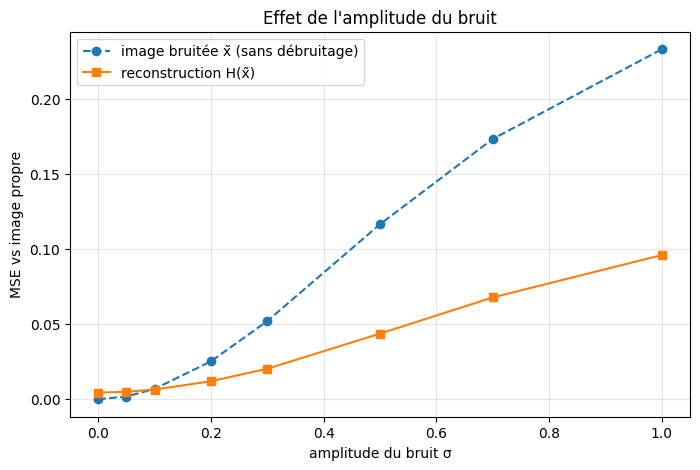

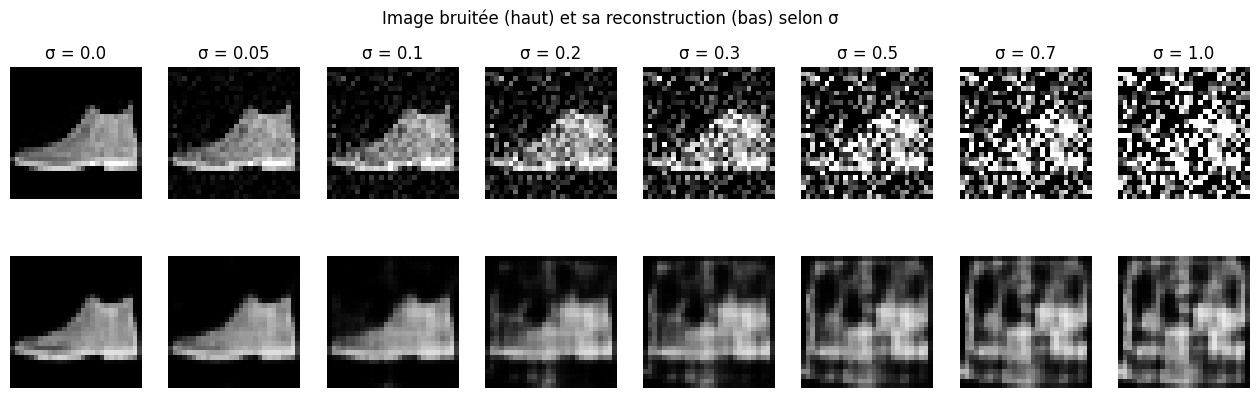

In [13]:
# =====================================================
# Bloc A — 1.3 — Question 5 : effet de l'amplitude σ du bruit
# =====================================================
sigmas = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
mse_bruitees, mse_recs, ex_b, ex_r = [], [], [], []
with torch.no_grad():
    for s in sigmas:
        torch.manual_seed(0)
        x_b = torch.clamp(x_test + s * torch.randn_like(x_test), 0, 1)   # x̃ puis troncature
        rec = ae_conv(x_b)                                               # H(x̃)
        mse_bruitees.append(((x_b - x_test)**2).mean().item())
        mse_recs.append(((rec - x_test)**2).mean().item())
        ex_b.append(x_b[0].cpu().squeeze()); ex_r.append(rec[0].cpu().squeeze())
        print(f"σ = {s:4.2f} | MSE bruitée = {mse_bruitees[-1]:.4f} | MSE reconstruite = {mse_recs[-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(sigmas, mse_bruitees, "o--", label="image bruitée x̃ (sans débruitage)")
plt.plot(sigmas, mse_recs, "s-", label="reconstruction H(x̃)")
plt.xlabel("amplitude du bruit σ"); plt.ylabel("MSE vs image propre")
plt.title("Effet de l'amplitude du bruit"); plt.legend(); plt.grid(alpha=0.3); plt.show()

fig, axes = plt.subplots(2, len(sigmas), figsize=(16, 4.5))
for j, s in enumerate(sigmas):
    axes[0, j].imshow(ex_b[j], cmap="gray", vmin=0, vmax=1); axes[0, j].set_title(f"σ = {s}"); axes[0, j].axis("off")
    axes[1, j].imshow(ex_r[j], cmap="gray", vmin=0, vmax=1); axes[1, j].axis("off")
plt.suptitle("Image bruitée (haut) et sa reconstruction (bas) selon σ"); plt.show()

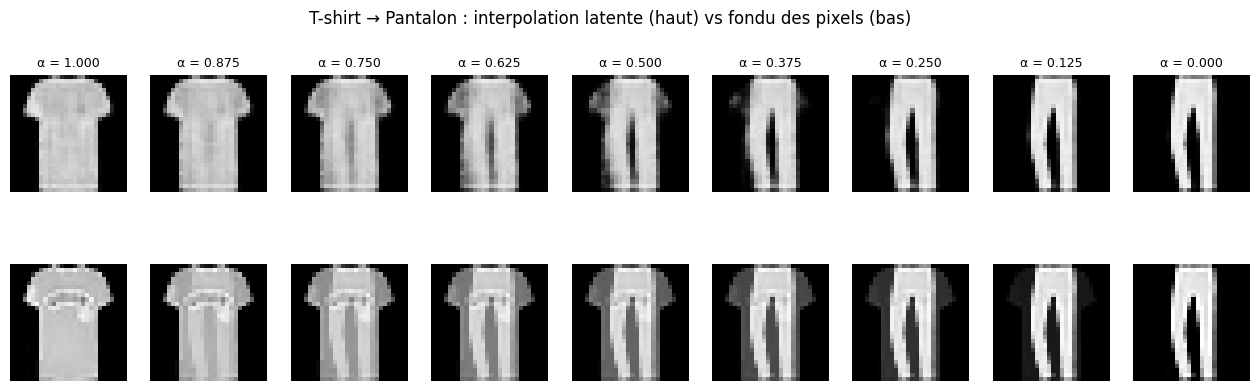

In [14]:
# =====================================================
# Bloc A — Livrable : interpolation latente  x_α = D(α z1 + (1 - α) z2)
# =====================================================
idx1 = (y_test == 0).nonzero()[0].item()         # premier T-shirt du lot de test
idx2 = (y_test == 1).nonzero()[0].item()         # premier pantalon
x1, x2 = x_test[idx1:idx1 + 1], x_test[idx2:idx2 + 1]
alphas = torch.linspace(1, 0, 9)                 # α de 1 (T-shirt) à 0 (pantalon)
with torch.no_grad():
    z1, z2 = ae_conv.encodeur(x1), ae_conv.encodeur(x2)
    latent = [ae_conv.decodeur(a * z1 + (1 - a) * z2).cpu().squeeze() for a in alphas]   # interpolation dans l'espace latent
    pixels = [(a * x1 + (1 - a) * x2).cpu().squeeze() for a in alphas]                   # simple fondu des pixels

fig, axes = plt.subplots(2, len(alphas), figsize=(16, 4.5))
for j, a in enumerate(alphas):
    axes[0, j].imshow(latent[j], cmap="gray", vmin=0, vmax=1); axes[0, j].set_title(f"α = {a:.3f}", fontsize=9); axes[0, j].axis("off")
    axes[1, j].imshow(pixels[j], cmap="gray", vmin=0, vmax=1); axes[1, j].axis("off")
plt.suptitle("T-shirt → Pantalon : interpolation latente (haut) vs fondu des pixels (bas)"); plt.show()

In [15]:
# =====================================================
# Bloc A — Questions de réflexion
# =====================================================
# Q1. Pourquoi un auto-encodeur peut-il débruiter sans avoir été explicitement conçu comme filtre ?
# L'auto-encodeur compresse chaque image de 784 pixels en un code de seulement 128 nombres
# (goulot d'étranglement). Pour bien reconstruire les images d'entraînement, il apprend à ne garder
# que les structures typiques des vêtements (silhouette, contours), et le décodeur ne sait produire
# que des images qui leur ressemblent. Le bruit gaussien est aléatoire et sans structure : il ne peut
# pas être représenté dans ce petit code et il est en grande partie éliminé. L'AE « projette » donc
# l'image bruitée vers l'image plausible la plus proche. Dans notre expérience, pour σ = 0,3,
# la MSE passe de 0,0521 (image bruitée) à 0,0203 (reconstruction), soit environ 61 % d'erreur en moins.
# Limite : pour un bruit très faible (σ = 0,05), l'AE dégrade l'image (0,0018 -> 0,0049), car son
# propre flou de reconstruction (≈ 0,0045) est plus grand que le bruit ; il devient utile dès σ = 0,1.
#
# Q2. En quoi l'AE convolutionnel est-il mieux adapté aux images que l'AE dense ?
# L'AE dense aplatit l'image en un vecteur : il perd la notion de voisinage entre pixels, et chaque
# neurone a des poids différents pour chaque position. L'AE convolutionnel applique de petits filtres
# qui traitent ensemble des pixels voisins (structure spatiale : bords, contours, textures), et le même
# filtre est utilisé sur toute l'image (partage des poids). Il a donc beaucoup moins de paramètres
# (843 649 contre 2 198 928) et reconstruit mieux : MSE de test de 0,0048 contre 0,0111 après
# 5 époques, avec des reconstructions plus nettes.
#
# Q3. Pourquoi l'interpolation dans un AE classique peut-elle traverser des régions peu plausibles ?
# L'AE classique est entraîné uniquement à reconstruire : la perte ne porte que sur les codes
# z = E(x) des images d'entraînement. Rien ne contrôle l'espace latent ENTRE ces codes, qui peut
# contenir des « trous » où le décodeur n'a jamais été entraîné. Quand on interpole linéairement
# entre le code d'un T-shirt et celui d'un pantalon, le chemin traverse ces zones et le décodeur
# produit des images floues ou hybrides, qui ne sont ni un T-shirt ni un pantalon. Le VAE (bloc B)
# corrige ce défaut grâce au terme KL, qui rend l'espace latent plus continu.
print("Réponses aux questions de réflexion du bloc A ajoutées.")

Réponses aux questions de réflexion du bloc A ajoutées.


In [2]:
# =====================================================
# Bloc B — Reprise (après redémarrage de Colab) : imports, données et fonctions utiles
# =====================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

transform = transforms.ToTensor()
train_set = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_set = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=0)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=0)
classes = ["T-shirt", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Basket", "Sac", "Bottine"]

x_batch, _ = next(iter(train_loader))            # un lot d'entraînement (pour les tests)
x_test, y_test = next(iter(test_loader))         # le même lot de test que dans le bloc A
x_test = x_test.to(device)

def afficher_lignes(lignes, titre, n=10, etiquettes=None, ref=None):
    fig, axes = plt.subplots(len(lignes), n, figsize=(16, 1.9 * len(lignes)))
    for r, (nom, images) in enumerate(lignes):
        for i in range(n):
            ax = axes[r, i]
            ax.imshow(images[i].cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
            if r == 0 and etiquettes is not None:
                ax.set_title(classes[etiquettes[i]], fontsize=9)
            elif ref is not None and r > 0:
                ax.set_title(f"MSE={((images[i] - ref[i])**2).mean().item():.4f}", fontsize=7)
            ax.axis("off")
        axes[r, 0].text(-8, 14, nom, fontsize=10, rotation=90, va="center", ha="center")
    plt.suptitle(titre); plt.show()

print("Reprise terminée : données et fonctions prêtes.")

Appareil utilisé : cuda


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 169kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.17MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.7MB/s]


Reprise terminée : données et fonctions prêtes.


In [3]:
# =====================================================
# Bloc B — Question 1 : encodeur convolutionnel produisant μ_φ(x) et log σ²_φ(x)
# =====================================================
latent_dim_vae = 16                              # dimension de l'espace latent du VAE

class EncodeurVAE(nn.Module):
    def __init__(self, latent_dim=latent_dim_vae):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.ReLU(),    # -> 32x14x14
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),   # -> 64x7x7
            nn.Flatten(),                                           # -> 3136
        )
        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)              # tête 1 : moyenne μ
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)          # tête 2 : log σ² (aucune contrainte de signe)
    def forward(self, x):
        h = self.conv(x)
        return self.fc_mu(h), self.fc_logvar(h)

# =====================================================
# Bloc B — Question 2 : décodeur convolutionnel transposé p_θ(x|z)
# =====================================================
class DecodeurVAE(nn.Module):
    def __init__(self, latent_dim=latent_dim_vae):
        super().__init__()
        self.depuis_latent = nn.Sequential(nn.Linear(latent_dim, 64 * 7 * 7), nn.ReLU())
        self.remettre_en_forme = nn.Unflatten(1, (64, 7, 7))
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),                                           # pixels entre 0 et 1
        )
    def forward(self, z):
        return self.deconv(self.remettre_en_forme(self.depuis_latent(z)))

# =====================================================
# Bloc B — Question 3 : reparamétrisation  z = μ + σ ⊙ ε,  ε ~ N(0, I)
# =====================================================
class VAE(nn.Module):
    def __init__(self, latent_dim=latent_dim_vae):
        super().__init__()
        self.encodeur = EncodeurVAE(latent_dim)
        self.decodeur = DecodeurVAE(latent_dim)
    def reparametrisation(self, mu, logvar):
        sigma = torch.exp(0.5 * logvar)          # σ = exp(½ log σ²) > 0
        epsilon = torch.randn_like(sigma)        # le hasard est isolé dans ε
        return mu + sigma * epsilon              # z ~ N(μ, σ²), dérivable par rapport à μ et σ
    def forward(self, x):
        mu, logvar = self.encodeur(x)
        z = self.reparametrisation(mu, logvar)
        return self.decodeur(z), mu, logvar

# ---- Tests ----
vae_test = VAE()
mu, logvar = vae_test.encodeur(x_batch)
print("Forme de μ :", mu.shape, "| forme de log σ² :", logvar.shape)
print("Forme de x' :", vae_test.decodeur(torch.randn(128, latent_dim_vae)).shape)
z = vae_test.reparametrisation(torch.full((10000, 1), 2.0), torch.full((10000, 1), float(np.log(0.25))))
print(f"Reparamétrisation (μ=2, σ=0.5) : moyenne = {z.mean().item():.3f} | écart-type = {z.std().item():.3f}")
mu_g = torch.tensor([[2.0]], requires_grad=True); lv_g = torch.tensor([[0.0]], requires_grad=True)
vae_test.reparametrisation(mu_g, lv_g).sum().backward()
print("Gradient dz/dμ :", mu_g.grad.item(), "| le gradient passe vers log σ² :", lv_g.grad is not None)

Forme de μ : torch.Size([128, 16]) | forme de log σ² : torch.Size([128, 16])
Forme de x' : torch.Size([128, 1, 28, 28])
Reparamétrisation (μ=2, σ=0.5) : moyenne = 1.997 | écart-type = 0.501
Gradient dz/dμ : 1.0 | le gradient passe vers log σ² : True


Test KL avec μ=0, σ=1 : 0.0000   (attendu 0)
Test KL avec μ=1, σ=1 : 8.0000   (attendu 8)
[β=1.0] Époque  1/15 | total = 297.5 | BCE = 281.2 | KL = 16.3 | test = 259.6
[β=1.0] Époque  2/15 | total = 253.6 | BCE = 235.5 | KL = 18.1 | test = 252.1
[β=1.0] Époque  3/15 | total = 249.0 | BCE = 231.0 | KL = 18.1 | test = 249.5
[β=1.0] Époque  4/15 | total = 246.9 | BCE = 228.8 | KL = 18.1 | test = 247.6
[β=1.0] Époque  5/15 | total = 245.5 | BCE = 227.4 | KL = 18.1 | test = 246.5
[β=1.0] Époque  6/15 | total = 244.5 | BCE = 226.5 | KL = 18.0 | test = 246.2
[β=1.0] Époque  7/15 | total = 243.8 | BCE = 225.8 | KL = 18.0 | test = 245.4
[β=1.0] Époque  8/15 | total = 243.2 | BCE = 225.2 | KL = 17.9 | test = 244.9
[β=1.0] Époque  9/15 | total = 242.7 | BCE = 224.8 | KL = 17.9 | test = 244.3
[β=1.0] Époque 10/15 | total = 242.3 | BCE = 224.4 | KL = 17.9 | test = 244.1
[β=1.0] Époque 11/15 | total = 241.9 | BCE = 224.1 | KL = 17.8 | test = 243.9
[β=1.0] Époque 12/15 | total = 241.6 | BCE = 223.8 |

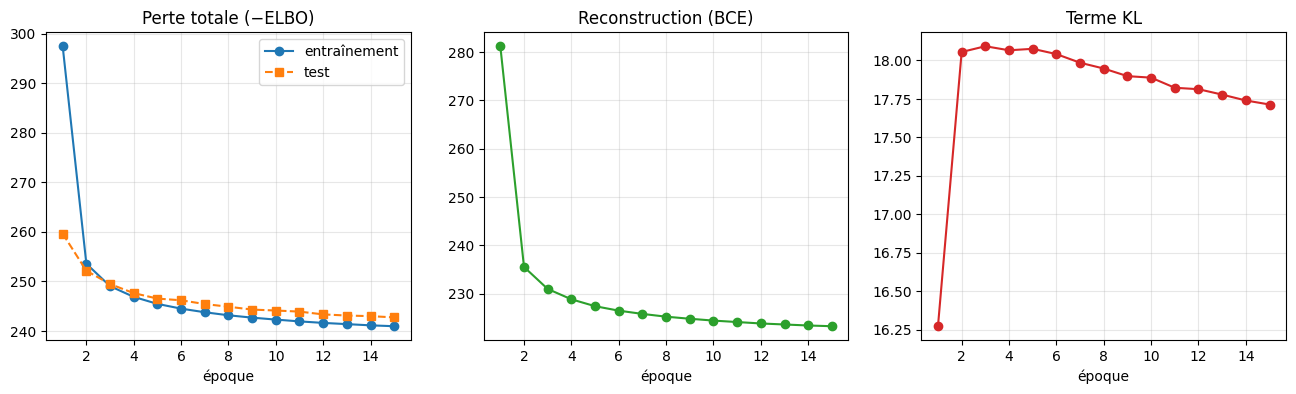

In [4]:
# =====================================================
# Bloc B — Question 4 : vae_loss(x_rec, x, mu, logvar)
# L_VAE = BCE(x', x) + β · D_KL( N(μ, σ²) || N(0, I) )
# =====================================================
def vae_loss(x_rec, x, mu, logvar, beta=1.0):
    batch = x.size(0)
    rec = F.binary_cross_entropy(x_rec, x, reduction="sum") / batch          # reconstruction : somme sur les pixels, moyenne par image
    kl = 0.5 * torch.sum(torch.exp(logvar) + mu**2 - 1 - logvar) / batch     # KL en forme fermée
    return rec + beta * kl, rec, kl

z0 = torch.zeros(4, latent_dim_vae); xf = torch.rand(4, 1, 28, 28)
print(f"Test KL avec μ=0, σ=1 : {vae_loss(xf, xf, z0, z0)[2].item():.4f}   (attendu 0)")
print(f"Test KL avec μ=1, σ=1 : {vae_loss(xf, xf, torch.ones(4, latent_dim_vae), z0)[2].item():.4f}   (attendu 8)")

# =====================================================
# Bloc B — Question 5 : entraîner le VAE sur FashionMNIST
# =====================================================
def entrainer_vae(beta=1.0, nb_epoques=15, graine=0, afficher=True):
    torch.manual_seed(graine)
    modele = VAE().to(device)
    optimizer = optim.Adam(modele.parameters(), lr=1e-3)
    hist = {"total": [], "rec": [], "kl": [], "test": []}
    for epoque in range(nb_epoques):
        modele.train(); st = sr = sk = 0.0
        for x, _ in train_loader:
            x = x.to(device)
            x_rec, mu, logvar = modele(x)
            total, rec, kl = vae_loss(x_rec, x, mu, logvar, beta)
            optimizer.zero_grad(); total.backward(); optimizer.step()
            n = x.size(0); st += total.item() * n; sr += rec.item() * n; sk += kl.item() * n
        Nt = len(train_set)
        hist["total"].append(st / Nt); hist["rec"].append(sr / Nt); hist["kl"].append(sk / Nt)
        modele.eval(); s = 0.0
        with torch.no_grad():
            for x, _ in test_loader:
                x = x.to(device); x_rec, mu, logvar = modele(x)
                s += vae_loss(x_rec, x, mu, logvar, beta)[0].item() * x.size(0)
        hist["test"].append(s / len(test_set))
        if afficher:
            print(f"[β={beta}] Époque {epoque+1:2d}/{nb_epoques} | total = {hist['total'][-1]:.1f} | "
                  f"BCE = {hist['rec'][-1]:.1f} | KL = {hist['kl'][-1]:.1f} | test = {hist['test'][-1]:.1f}")
    return modele, hist

vae, hist_vae = entrainer_vae(beta=1.0, nb_epoques=15)

# ---- Visualisation attendue : courbes de perte (reconstruction et KL) ----
ep = range(1, len(hist_vae["total"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(ep, hist_vae["total"], "o-", label="entraînement"); ax[0].plot(ep, hist_vae["test"], "s--", label="test")
ax[0].set_title("Perte totale (−ELBO)"); ax[0].legend()
ax[1].plot(ep, hist_vae["rec"], "o-", color="C2"); ax[1].set_title("Reconstruction (BCE)")
ax[2].plot(ep, hist_vae["kl"], "o-", color="C3"); ax[2].set_title("Terme KL")
for a in ax: a.set_xlabel("époque"); a.grid(alpha=0.3)
plt.show()

MSE de reconstruction du VAE (latent 16) : 0.0117


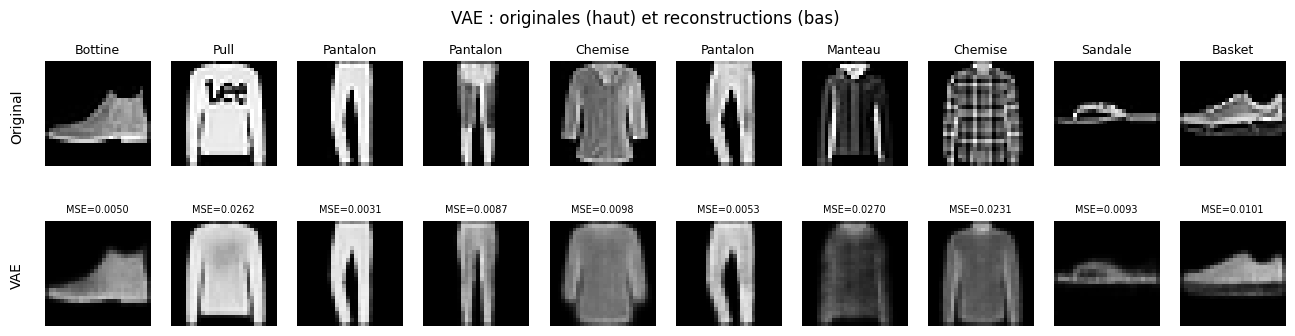

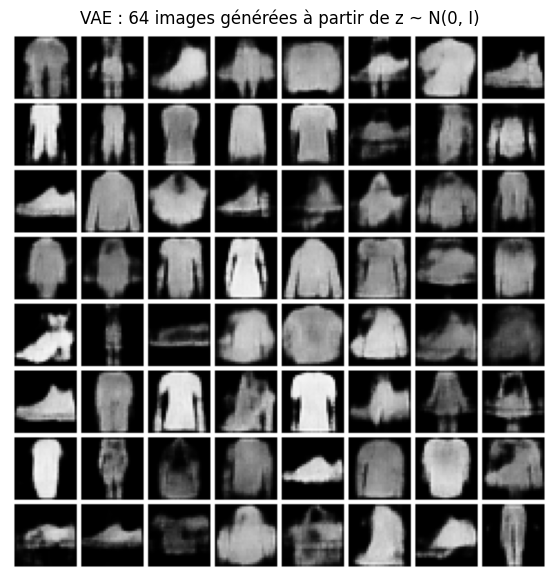

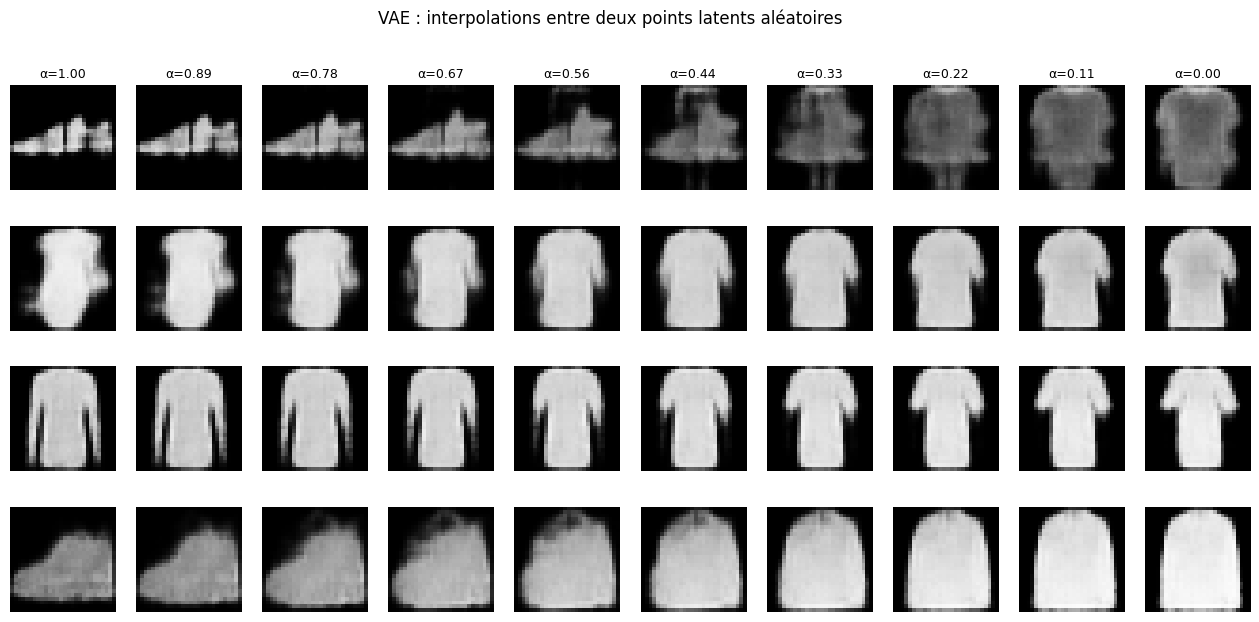

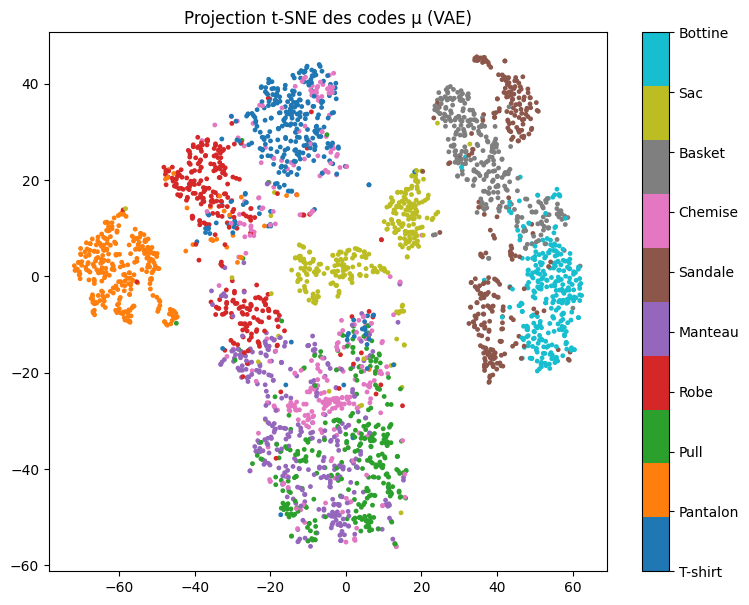

Bloc B terminé.


In [5]:
# =====================================================
# Bloc B — Visualisation : reconstructions du VAE (z = μ)
# =====================================================
vae.eval()
with torch.no_grad():
    mu, _ = vae.encodeur(x_test)
    rec_vae = vae.decodeur(mu)                   # reconstruction la plus probable (sans tirage aléatoire)
print(f"MSE de reconstruction du VAE (latent 16) : {((rec_vae - x_test)**2).mean().item():.4f}")
afficher_lignes([("Original", x_test), ("VAE", rec_vae)],
                "VAE : originales (haut) et reconstructions (bas)", etiquettes=y_test, ref=x_test)

# =====================================================
# Bloc B — Question 6 : générer des images avec z ~ N(0, I)
# =====================================================
def grille(images, nrow=8):
    return torchvision.utils.make_grid(images.cpu(), nrow=nrow, padding=2, pad_value=1).permute(1, 2, 0)

torch.manual_seed(0)
with torch.no_grad():
    gen_vae = vae.decodeur(torch.randn(64, latent_dim_vae, device=device))   # décodeur seul : x = D(z)
plt.figure(figsize=(7, 7)); plt.imshow(grille(gen_vae)); plt.axis("off")
plt.title("VAE : 64 images générées à partir de z ~ N(0, I)"); plt.show()

# =====================================================
# Bloc B — Question 7 : interpoler entre deux points latents aléatoires
# =====================================================
alphas = torch.linspace(1, 0, 10)
torch.manual_seed(1)
fig, axes = plt.subplots(4, len(alphas), figsize=(16, 7))
with torch.no_grad():
    for r in range(4):
        z1 = torch.randn(1, latent_dim_vae, device=device)    # point latent aléatoire 1
        z2 = torch.randn(1, latent_dim_vae, device=device)    # point latent aléatoire 2
        for j, a in enumerate(alphas):
            img = vae.decodeur(a * z1 + (1 - a) * z2).cpu().squeeze()
            axes[r, j].imshow(img, cmap="gray", vmin=0, vmax=1); axes[r, j].axis("off")
            if r == 0: axes[r, j].set_title(f"α={a:.2f}", fontsize=9)
plt.suptitle("VAE : interpolations entre deux points latents aléatoires"); plt.show()

# =====================================================
# Bloc B — Visualisation : projection t-SNE des codes μ du VAE
# =====================================================
codes, etiquettes = [], []
with torch.no_grad():
    for x, y in test_loader:
        codes.append(vae.encodeur(x.to(device))[0].cpu()); etiquettes.append(y)
        if sum(len(c) for c in codes) >= 3000: break
codes = torch.cat(codes)[:3000].numpy(); etiquettes = torch.cat(etiquettes)[:3000].numpy()
codes_2d = TSNE(n_components=2, random_state=0).fit_transform(codes)
plt.figure(figsize=(9, 7))
nuage = plt.scatter(codes_2d[:, 0], codes_2d[:, 1], c=etiquettes, cmap="tab10", s=6)
cbar = plt.colorbar(nuage, ticks=range(10)); cbar.ax.set_yticklabels(classes)
plt.title("Projection t-SNE des codes μ (VAE)"); plt.show()

# =====================================================
# Bloc B — Question 8 (optionnelle, non traitée) : effet de β
# Commentaire : un petit β favorise la reconstruction (images plus nettes, KL élevé, espace latent
# moins régulier) ; un grand β (β-VAE) force les codes vers N(0, I) : espace latent plus lisse et
# plus « démêlé », mais reconstructions plus floues. β règle le compromis fidélité / générativité.
#
# =====================================================
# Bloc B — Questions de réflexion
# =====================================================
# Q1. Pourquoi le VAE produit-il un espace latent plus régulier que l'AE ?
# L'encodeur produit une distribution N(μ, σ²) et non un point : pendant l'entraînement, le décodeur
# doit bien reconstruire pour des z tirés autour de μ, donc des codes voisins donnent des images
# voisines. Le terme KL rapproche toutes ces distributions de N(0, I), ce qui remplit l'espace latent
# sans « trous ». Les images générées à partir de z ~ N(0, I) et les interpolations sont donc plausibles.
#
# Q2. Quel compromis impose la KL entre fidélité de reconstruction et générativité ?
# Pour bien reconstruire, l'encodeur voudrait des gaussiennes étroites et éloignées les unes des autres
# (KL élevé). La KL les pousse vers N(0, I) : l'espace latent devient régulier et bon pour générer,
# mais le code transmet moins d'information sur l'image. Pendant l'entraînement, la BCE baisse de 281 à 223
# tandis que le KL monte à environ 18 puis se stabilise : le modèle trouve un équilibre entre les deux.
# Résultat : les reconstructions du VAE sont moins fidèles que celles de l'AE convolutionnel.
#
# Q3. Pourquoi les échantillons du VAE peuvent-ils sembler plus flous ?
# La perte de reconstruction pixel par pixel (BCE) pénalise l'erreur moyenne : face à l'incertitude,
# le décodeur produit la moyenne des images possibles, qui est floue. De plus, la contrainte KL limite
# l'information contenue dans z (16 dimensions seulement), donc les détails fins ne sont pas encodés.
print("Bloc B terminé.")

In [6]:
# =====================================================
# Bloc C — Question 1 : charger MNIST et encoder les étiquettes en one-hot (taille 10)
# =====================================================
mnist_train = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
mnist_test = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())
mnist_loader = DataLoader(mnist_train, batch_size=128, shuffle=True, num_workers=0)
mnist_test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False, num_workers=0)
nb_classes = 10
xm, ym = next(iter(mnist_loader))
print("Exemple : étiquette", ym[0].item(), "-> one-hot", F.one_hot(ym, nb_classes)[0].numpy())

latent_dim_cvae = 16

# =====================================================
# Bloc C — Question 2 : encodeur q_φ(z | x, y)
# Bloc C — Question 4 : y est concaténé à la représentation intermédiaire de l'image
# =====================================================
class EncodeurCVAE(nn.Module):
    def __init__(self, latent_dim=latent_dim_cvae):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
            nn.Flatten(),                                                    # caractéristiques de l'image : 3136
        )
        self.fc = nn.Sequential(nn.Linear(64 * 7 * 7 + nb_classes, 256), nn.ReLU())   # [h(x), y] -> 256
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
    def forward(self, x, y_oh):
        h = torch.cat([self.conv(x), y_oh], dim=1)                           # concaténation de y
        h = self.fc(h)
        return self.fc_mu(h), self.fc_logvar(h)

# =====================================================
# Bloc C — Question 3 : décodeur p_θ(x | z, y)
# Bloc C — Question 4 : y est concaténé au code z
# =====================================================
class DecodeurCVAE(nn.Module):
    def __init__(self, latent_dim=latent_dim_cvae):
        super().__init__()
        self.depuis_latent = nn.Sequential(nn.Linear(latent_dim + nb_classes, 64 * 7 * 7), nn.ReLU())   # [z, y] -> 3136
        self.remettre_en_forme = nn.Unflatten(1, (64, 7, 7))
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),
        )
    def forward(self, z, y_oh):
        return self.deconv(self.remettre_en_forme(self.depuis_latent(torch.cat([z, y_oh], dim=1))))

class CVAE(nn.Module):
    def __init__(self, latent_dim=latent_dim_cvae):
        super().__init__()
        self.encodeur = EncodeurCVAE(latent_dim)
        self.decodeur = DecodeurCVAE(latent_dim)
    def forward(self, x, y_oh):
        mu, logvar = self.encodeur(x, y_oh)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)              # reparamétrisation
        return self.decodeur(z, y_oh), mu, logvar

# =====================================================
# Bloc C — Question 5 : entraîner avec la perte conditionnelle L_CVAE = -ELBO(x, y)
# =====================================================
torch.manual_seed(0)
cvae = CVAE().to(device)
opt_cvae = optim.Adam(cvae.parameters(), lr=1e-3)
for epoque in range(10):
    cvae.train(); sr = sk = 0.0
    for x, y in mnist_loader:
        x = x.to(device); y_oh = F.one_hot(y, nb_classes).float().to(device)
        x_rec, mu, logvar = cvae(x, y_oh)
        total, rec, kl = vae_loss(x_rec, x, mu, logvar)                     # même perte, conditionnée par y
        opt_cvae.zero_grad(); total.backward(); opt_cvae.step()
        sr += rec.item() * x.size(0); sk += kl.item() * x.size(0)
    print(f"[CVAE] Époque {epoque+1:2d}/10 | BCE = {sr/len(mnist_train):.1f} | KL = {sk/len(mnist_train):.1f}")

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.00MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.2MB/s]


Exemple : étiquette 7 -> one-hot [0 0 0 0 0 0 0 1 0 0]
[CVAE] Époque  1/10 | BCE = 178.4 | KL = 12.6
[CVAE] Époque  2/10 | BCE = 99.4 | KL = 19.5
[CVAE] Époque  3/10 | BCE = 87.7 | KL = 21.2
[CVAE] Époque  4/10 | BCE = 83.9 | KL = 21.5
[CVAE] Époque  5/10 | BCE = 81.7 | KL = 21.6
[CVAE] Époque  6/10 | BCE = 80.2 | KL = 21.5
[CVAE] Époque  7/10 | BCE = 79.2 | KL = 21.5
[CVAE] Époque  8/10 | BCE = 78.5 | KL = 21.5
[CVAE] Époque  9/10 | BCE = 77.9 | KL = 21.4
[CVAE] Époque 10/10 | BCE = 77.3 | KL = 21.3


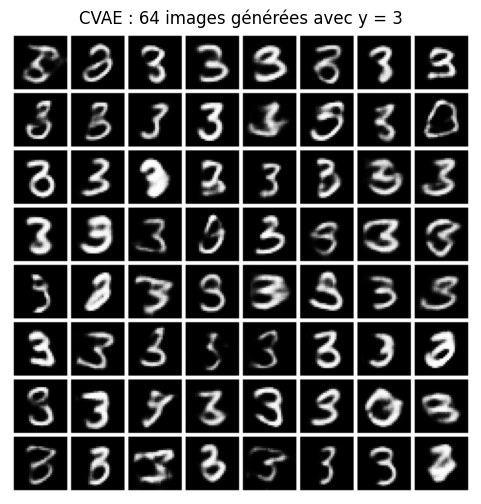

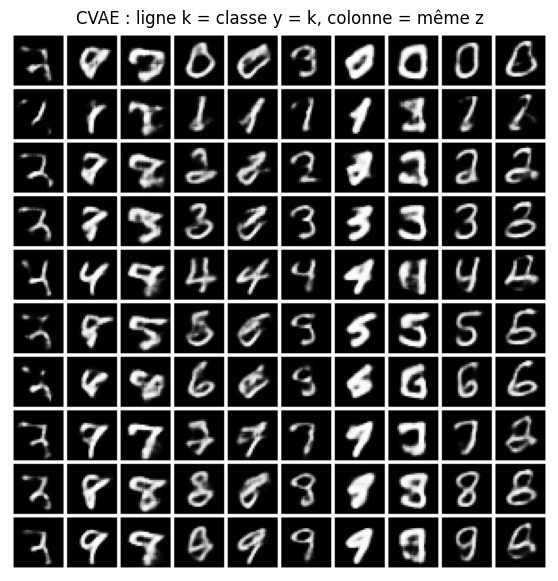

Précision du classifieur sur les vraies images de test : 98.34 %
Fidélité par classe (%) : [84.8, 84.8, 70.8, 82.2, 94.8, 83.4, 76.4, 82.2, 77.2, 71.8]
Fidélité moyenne : 80.8 %


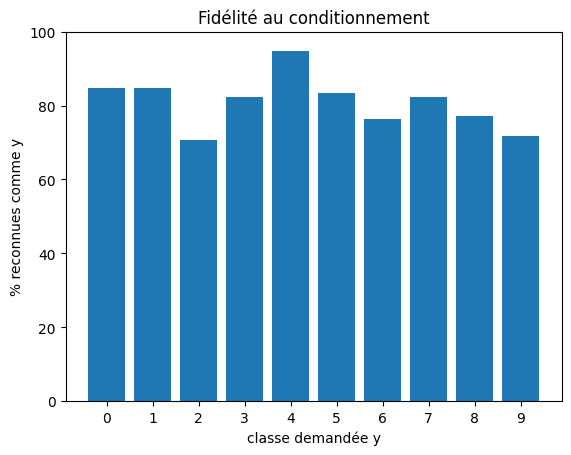

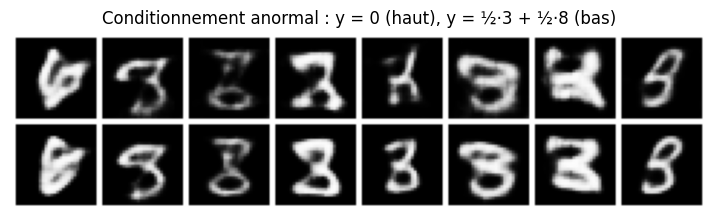

Bloc C terminé.


In [7]:
# =====================================================
# Bloc C — Question 6 : choisir une classe y et générer des images avec z ~ N(0, I)
# =====================================================
def grille(images, nrow=8):
    return torchvision.utils.make_grid(images.cpu(), nrow=nrow, padding=2, pad_value=1).permute(1, 2, 0)

cvae.eval()
classe_choisie = 3
torch.manual_seed(0)
with torch.no_grad():
    z = torch.randn(64, latent_dim_cvae, device=device)
    y_oh = F.one_hot(torch.full((64,), classe_choisie, device=device), nb_classes).float()
    gen = cvae.decodeur(z, y_oh)
plt.figure(figsize=(6, 6)); plt.imshow(grille(gen)); plt.axis("off")
plt.title(f"CVAE : 64 images générées avec y = {classe_choisie}"); plt.show()

# =====================================================
# Bloc C — Question 7 : plusieurs classes (ligne = classe, colonne = même z)
# =====================================================
torch.manual_seed(1)
with torch.no_grad():
    z_fixe = torch.randn(10, latent_dim_cvae, device=device).repeat(10, 1)
    y_fixe = torch.arange(10, device=device).repeat_interleave(10)
    gen_grille = cvae.decodeur(z_fixe, F.one_hot(y_fixe, nb_classes).float())
plt.figure(figsize=(7, 7)); plt.imshow(grille(gen_grille, nrow=10)); plt.axis("off")
plt.title("CVAE : ligne k = classe y = k, colonne = même z"); plt.show()

# ---- Fidélité au conditionnement mesurée par un petit classifieur entraîné sur MNIST ----
torch.manual_seed(0)
classifieur = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
opt_c = optim.Adam(classifieur.parameters(), lr=1e-3)
for _ in range(2):                                                 # 2 époques suffisent (~99 %)
    for x, y in mnist_loader:
        perte = F.cross_entropy(classifieur(x.to(device)), y.to(device))
        opt_c.zero_grad(); perte.backward(); opt_c.step()
classifieur.eval(); bonnes = 0
with torch.no_grad():
    for x, y in mnist_test_loader:
        bonnes += (classifieur(x.to(device)).argmax(1).cpu() == y).sum().item()
print(f"Précision du classifieur sur les vraies images de test : {100 * bonnes / len(mnist_test):.2f} %")

fidelite = []
with torch.no_grad():
    for k in range(10):
        z = torch.randn(500, latent_dim_cvae, device=device)
        pred = classifieur(cvae.decodeur(z, F.one_hot(torch.full((500,), k, device=device), nb_classes).float())).argmax(1)
        fidelite.append((pred == k).float().mean().item())
print("Fidélité par classe (%) :", [round(100 * f, 1) for f in fidelite])
print(f"Fidélité moyenne : {100 * np.mean(fidelite):.1f} %")
plt.bar(range(10), [100 * f for f in fidelite]); plt.ylim(0, 100); plt.xticks(range(10))
plt.xlabel("classe demandée y"); plt.ylabel("% reconnues comme y"); plt.title("Fidélité au conditionnement"); plt.show()

# ---- Conditionnement anormal : aucune classe, ou mélange 3 / 8 ----
with torch.no_grad():
    z = torch.randn(8, latent_dim_cvae, device=device)
    y_vide = torch.zeros(8, nb_classes, device=device)
    y_melange = 0.5 * F.one_hot(torch.full((8,), 3, device=device), nb_classes).float() \
              + 0.5 * F.one_hot(torch.full((8,), 8, device=device), nb_classes).float()
    imgs = torch.cat([cvae.decodeur(z, y_vide), cvae.decodeur(z, y_melange)])
plt.figure(figsize=(9, 2.8)); plt.imshow(grille(imgs, nrow=8)); plt.axis("off")
plt.title("Conditionnement anormal : y = 0 (haut), y = ½·3 + ½·8 (bas)"); plt.show()

# =====================================================
# Bloc C — Questions de réflexion
# =====================================================
# Q1. En quoi le CVAE ajoute-t-il un contrôle absent du VAE standard ?
# Avec un VAE, on tire z au hasard et on ne choisit pas ce qui est généré. Avec le CVAE, on donne la
# classe y au décodeur : on choisit le chiffre, et z ne code plus que le style (épaisseur, inclinaison).
# Sur la grille, chaque ligne contient le chiffre demandé et chaque colonne garde le même style.
#
# Q2. Que se passe-t-il si le conditionnement est mal injecté dans l'encodeur ou le décodeur ?
# Si y n'est pas donné au décodeur, il ne peut pas l'utiliser : la classe générée redevient aléatoire.
# Si y n'est pas donné à l'encodeur, celui-ci doit coder la classe dans z, ce qui fait doublon et peut
# entrer en conflit avec y à la génération. Avec un y anormal (vecteur nul ou mélange 3/8), le décodeur
# produit des chiffres ambigus, car il n'a jamais vu de tels conditionnements.
#
# Q3. La qualité visuelle suffit-elle à évaluer un modèle conditionnel ?
# Non : des images nettes peuvent ne pas respecter la classe demandée ou manquer de diversité. Il faut
# aussi mesurer la fidélité au conditionnement (ici avec un classifieur indépendant), la diversité
# à l'intérieur d'une classe, et éventuellement des métriques comme la FID ou la vraisemblance.
print("Bloc C terminé.")

In [8]:
# Bloc C — Question 7 : commentaire sur la fidélité au conditionnement
# Le classifieur atteint 98,34 % sur les vraies images de test : il est fiable pour juger les images
# générées. En moyenne, 80,8 % des images générées par le CVAE sont reconnues comme la classe demandée :
# le conditionnement est bien respecté, mais pas parfaitement. Le 4 est le mieux généré (94,8 %), alors
# que le 2 (70,8 %) et le 9 (71,8 %) sont les moins fidèles : certains échantillons sont flous ou ambigus
# (forme intermédiaire entre deux chiffres), ce qui illustre le flou typique des VAE.
print("Commentaire ajouté.")

Commentaire ajouté.


Cibles discrètes : torch.Size([128, 28, 28]) torch.int64 | min = 0 | max = 255


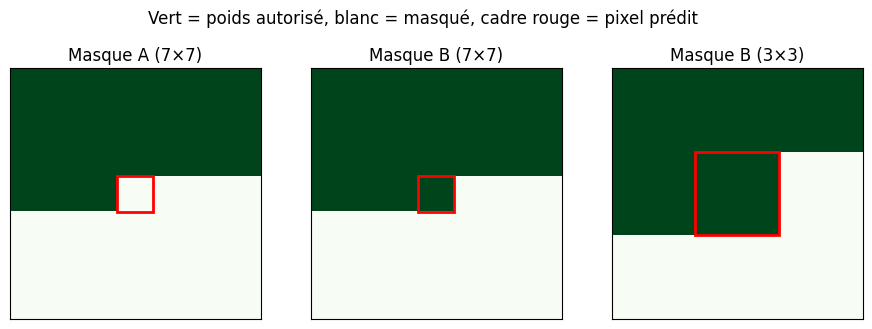

Forme de la sortie : torch.Size([4, 256, 28, 28])
Nombre de paramètres : 242304
Changement max sur les pixels jusqu'à (14,14) inclus : 2.2118911147117615e-07 (doit être 0)


In [9]:
# =====================================================
# Bloc D — Question 1 : FashionMNIST discrétisé en 256 niveaux (0..255)
# =====================================================
import time
pix_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=0)
pix_test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=0)

def discretiser(x):                              # pixels [0, 1] -> entiers 0..255
    return (x * 255).round().long().squeeze(1)   # forme (batch, 28, 28)

xd = discretiser(next(iter(pix_loader))[0])
print("Cibles discrètes :", xd.shape, xd.dtype, "| min =", xd.min().item(), "| max =", xd.max().item())

# =====================================================
# Bloc D — Question 2 : classe MaskedConv2d héritant de nn.Conv2d
# Bloc D — Question 3 : masques de type A (exclut le pixel courant) et B (l'inclut)
# =====================================================
class MaskedConv2d(nn.Conv2d):
    def __init__(self, type_masque, *args, **kwargs):
        super().__init__(*args, **kwargs)
        _, _, kh, kw = self.weight.shape
        masque = torch.ones_like(self.weight)
        masque[:, :, kh // 2, kw // 2 + (type_masque == "B"):] = 0   # ligne du centre : pixels à droite (+ le centre pour A)
        masque[:, :, kh // 2 + 1:, :] = 0                            # toutes les lignes en dessous
        self.register_buffer("masque", masque)
    def forward(self, x):
        return F.conv2d(x, self.weight * self.masque, self.bias,      # W_masked = W ⊙ M
                        self.stride, self.padding, self.dilation, self.groups)

# ---- Visualisation attendue : illustration des masques A et B ----
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (t, k) in zip(axes, [("A", 7), ("B", 7), ("B", 3)]):
    m = MaskedConv2d(t, 1, 1, k).masque[0, 0]
    ax.imshow(m, cmap="Greens", vmin=0, vmax=1)
    c = k // 2
    ax.add_patch(plt.Rectangle((c - 0.5, c - 0.5), 1, 1, fill=False, edgecolor="red", lw=2))   # pixel prédit
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"Masque {t} ({k}×{k})")
plt.suptitle("Vert = poids autorisé, blanc = masqué, cadre rouge = pixel prédit"); plt.show()

# =====================================================
# Bloc D — Question 4 : PixelCNN (1 couche A 7x7, 6 couches B 3x3, 256 logits par pixel)
# =====================================================
class PixelCNN(nn.Module):
    def __init__(self, canaux=64, nb_couches_B=6, K=256):
        super().__init__()
        couches = [MaskedConv2d("A", 1, canaux, 7, padding=3), nn.BatchNorm2d(canaux), nn.ReLU()]
        for _ in range(nb_couches_B):
            couches += [MaskedConv2d("B", canaux, canaux, 3, padding=1), nn.BatchNorm2d(canaux), nn.ReLU()]
        couches += [nn.Conv2d(canaux, K, 1)]     # convolution 1x1 : 256 logits par pixel
        self.reseau = nn.Sequential(*couches)
    def forward(self, x):
        return self.reseau(x)                    # (batch, 256, 28, 28)

pixelcnn = PixelCNN().to(device)
print("Forme de la sortie :", pixelcnn(xd[:4].unsqueeze(1).float().to(device) / 255).shape)
print("Nombre de paramètres :", sum(p.numel() for p in pixelcnn.parameters()))

# ---- Vérification de la causalité : modifier le pixel (14,14) ne doit pas changer les prédictions avant lui ----
pixelcnn.eval()
x0 = torch.rand(1, 1, 28, 28, device=device)
x1_ = x0.clone(); x1_[0, 0, 14, 14] += 1.0
with torch.no_grad():
    diff = (pixelcnn(x0) - pixelcnn(x1_)).abs().sum(1)[0]
avant = torch.zeros(28, 28, dtype=torch.bool); avant[:14, :] = True; avant[14, :15] = True
print("Changement max sur les pixels jusqu'à (14,14) inclus :", diff[avant].max().item(), "(doit être 0)")

[PixelCNN] Époque 1/5 | train = 2.602 | test = 2.228 nats/pixel (3.21 bits/pixel) | 36 s
[PixelCNN] Époque 2/5 | train = 2.183 | test = 2.175 nats/pixel (3.14 bits/pixel) | 35 s
[PixelCNN] Époque 3/5 | train = 2.136 | test = 2.127 nats/pixel (3.07 bits/pixel) | 34 s
[PixelCNN] Époque 4/5 | train = 2.109 | test = 2.111 nats/pixel (3.05 bits/pixel) | 34 s
[PixelCNN] Époque 5/5 | train = 2.091 | test = 2.087 nats/pixel (3.01 bits/pixel) | 34 s


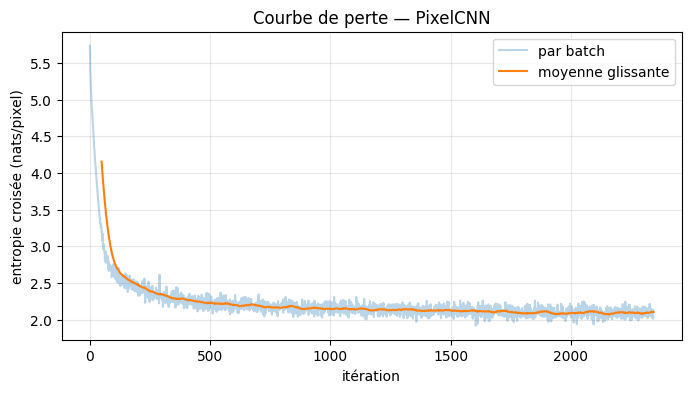

Erreur absolue moyenne pixel prédit / pixel réel : 12.6 niveaux (sur 255)


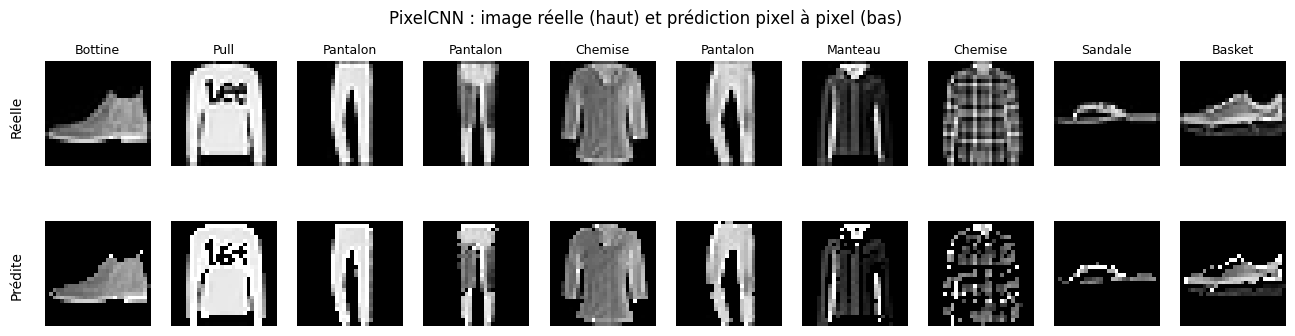

Génération de 16 images en 1.7 s (784 passes du réseau)


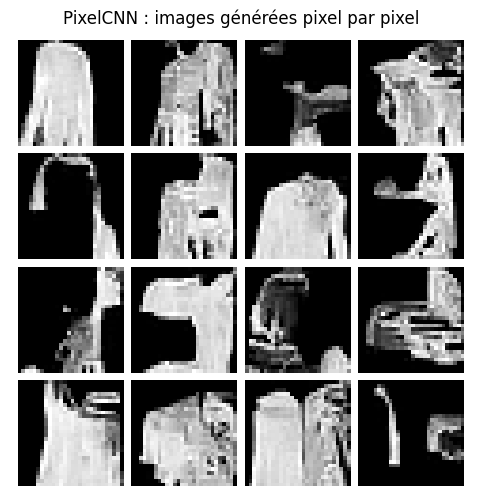

Bloc D terminé — TP 2 complet !


In [10]:
# =====================================================
# Bloc D — Question 5 : entraîner le PixelCNN avec CrossEntropyLoss
# =====================================================
torch.manual_seed(0)
pixelcnn = PixelCNN().to(device)
opt_px = optim.Adam(pixelcnn.parameters(), lr=1e-3)
critere_px = nn.CrossEntropyLoss()               # moyenne de -log p(x_i | x_<i) sur tous les pixels
hist_px = []
for epoque in range(5):
    pixelcnn.train(); s = 0.0; t0 = time.time()
    for x, _ in pix_loader:
        cible = discretiser(x).to(device)        # niveaux 0..255 à prédire
        perte = critere_px(pixelcnn(cible.unsqueeze(1).float() / 255), cible)
        opt_px.zero_grad(); perte.backward(); opt_px.step()
        hist_px.append(perte.item()); s += perte.item() * x.size(0)
    pixelcnn.eval(); st = 0.0
    with torch.no_grad():
        for x, _ in pix_test_loader:
            cible = discretiser(x).to(device)
            st += critere_px(pixelcnn(cible.unsqueeze(1).float() / 255), cible).item() * x.size(0)
    st /= len(test_set)
    print(f"[PixelCNN] Époque {epoque+1}/5 | train = {s/len(train_set):.3f} | test = {st:.3f} nats/pixel "
          f"({st/np.log(2):.2f} bits/pixel) | {time.time()-t0:.0f} s")

# ---- Visualisation attendue : courbe de perte d'entraînement ----
lissee = np.convolve(hist_px, np.ones(50) / 50, mode="valid")
plt.figure(figsize=(8, 4))
plt.plot(hist_px, alpha=0.3, label="par batch"); plt.plot(range(49, 49 + len(lissee)), lissee, label="moyenne glissante")
plt.xlabel("itération"); plt.ylabel("entropie croisée (nats/pixel)"); plt.title("Courbe de perte — PixelCNN")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# =====================================================
# Bloc D — Question 6 : prédictions pixel à pixel sur des images de test
# =====================================================
pixelcnn.eval()
xt, yt = next(iter(pix_test_loader))
cible = discretiser(xt[:10]).to(device)
with torch.no_grad():
    pred = pixelcnn(cible.unsqueeze(1).float() / 255).argmax(1)    # niveau le plus probable pour chaque pixel
print(f"Erreur absolue moyenne pixel prédit / pixel réel : {(pred - cible).abs().float().mean().item():.1f} niveaux (sur 255)")
afficher_lignes([("Réelle", cible.unsqueeze(1).float() / 255), ("Prédite", pred.unsqueeze(1).float() / 255)],
                "PixelCNN : image réelle (haut) et prédiction pixel à pixel (bas)", etiquettes=yt[:10])

# =====================================================
# Bloc D — Question 7 : génération séquentielle à partir d'une image vide
# =====================================================
torch.manual_seed(0)
images = torch.zeros(16, 1, 28, 28, device=device)   # image vide
t0 = time.time()
with torch.no_grad():
    for i in range(28):
        for j in range(28):
            probas = F.softmax(pixelcnn(images)[:, :, i, j], dim=1)   # p(x_ij | pixels déjà générés)
            images[:, 0, i, j] = torch.multinomial(probas, 1).squeeze(1).float() / 255
print(f"Génération de 16 images en {time.time()-t0:.1f} s ({28*28} passes du réseau)")
plt.figure(figsize=(6, 6))
plt.imshow(torchvision.utils.make_grid(images.cpu(), nrow=4, padding=2, pad_value=1).permute(1, 2, 0))
plt.axis("off"); plt.title("PixelCNN : images générées pixel par pixel"); plt.show()

# =====================================================
# Bloc D — Questions de réflexion
# =====================================================
# Q1. Pourquoi PixelCNN respecte-t-il la causalité auto-régressive ?
# Les masques mettent à zéro les poids qui regardent le pixel courant (masque A, 1re couche) et les
# pixels suivants (à droite et en dessous). Les couches suivantes (masque B) peuvent utiliser la position
# courante, car elle ne contient déjà plus que de l'information sur les pixels précédents. La prédiction
# du pixel i ne dépend donc que de x_<i, ce que confirme notre test (changement nul, à l'arrondi près).
#
# Q2. Pourquoi la génération est-elle séquentielle et coûteuse ?
# Chaque pixel est tiré selon p(x_i | x_<i) : il faut connaître tous les pixels précédents avant de
# générer le suivant. Il faut donc 784 passes du réseau pour une image 28x28 (et des millions pour une
# grande image), alors que l'entraînement traite tous les pixels en parallèle grâce aux masques.
#
# Q3. Avantages de PixelCNN par rapport à un modèle latent, et inversement ?
# PixelCNN : vraisemblance exacte et calculable, entraînement stable (simple entropie croisée),
# bonne modélisation des détails locaux. Mais génération lente, pas d'espace latent (pas
# d'interpolation ni de représentation compacte), et cohérence globale parfois faible.
# VAE : génération en une seule passe et espace latent exploitable, mais vraisemblance seulement
# approchée (ELBO) et images souvent plus floues.
#
# Limites computationnelles : coût de génération proportionnel au nombre de pixels, champ réceptif
# limité (« angle mort » des convolutions masquées). Solutions : Gated PixelCNN, mise en cache,
# modèles autorégressifs sur des tokens visuels compressés (VQ-VAE + Transformer).
print("Bloc D terminé — TP 2 complet !")